# Practical No. 04: Image Generation using Deep Convolutional GAN (DCGAN)

**Name:** Mit Jangid  
**PRN:** 202401110072  
**Batch:** A1  
**Subject:** Generative AI

## Aim
Implement and train a Deep Convolutional Generative Adversarial Network (DCGAN) on a standard image dataset, generate synthetic images, and evaluate performance using Generator and Discriminator loss curves and the quality of generated images.

## Dataset and efficiency choice
This implementation uses **MNIST** (28×28 grayscale handwritten digits). To keep Colab training practical, it uses a reproducible 20,000-image subset of the 60,000-image training set. The held-out test set is loaded for visual reference only; GAN training is unsupervised and does not use labels.

**Runtime note:** Select a GPU runtime in Colab. Actual training time depends on the assigned hardware. The notebook starts with 15 epochs and saves sample grids during training.

## 1. Import libraries and set reproducibility

In [1]:
import os, time, random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Load and prepare MNIST
Images are scaled to [-1, 1], matching the Generator's tanh output.

In [2]:
(x_train, _), (x_test, _) = keras.datasets.mnist.load_data()

# Reproducible subset for faster training
rng = np.random.default_rng(SEED)
subset_idx = rng.choice(len(x_train), size=20000, replace=False)
x_train = x_train[subset_idx]

x_train = (x_train.astype("float32") - 127.5) / 127.5
x_train = np.expand_dims(x_train, axis=-1)

BATCH_SIZE = 128
BUFFER_SIZE = len(x_train)

train_ds = (
    tf.data.Dataset.from_tensor_slices(x_train)
    .shuffle(BUFFER_SIZE, seed=SEED, reshuffle_each_iteration=True)
    .batch(BATCH_SIZE, drop_remainder=True)
    .prefetch(tf.data.AUTOTUNE)
)

print("Training subset:", x_train.shape)
print("Test set (visual reference):", x_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training subset: (20000, 28, 28, 1)
Test set (visual reference): (10000, 28, 28)


## 3. Visualize real training images

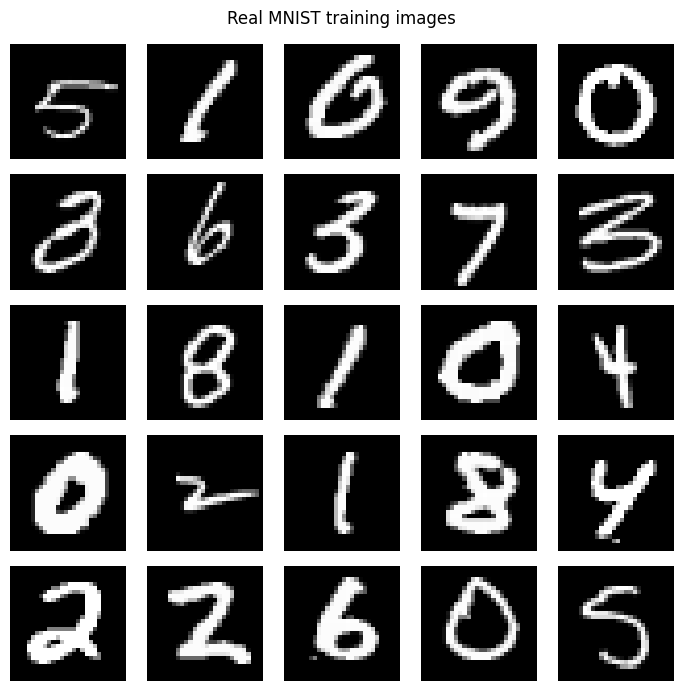

In [3]:
plt.figure(figsize=(7, 7))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(x_train[i].squeeze(), cmap="gray", vmin=-1, vmax=1)
    plt.axis("off")
plt.suptitle("Real MNIST training images")
plt.tight_layout()
plt.show()

## 4. Build the Generator
The Generator maps a 64-dimensional random noise vector to a 28×28 grayscale image. Batch normalization and ReLU activations help stabilize upsampling; tanh produces pixels in [-1, 1].

In [4]:
LATENT_DIM = 64

def build_generator():
    model = keras.Sequential(name="Generator")
    model.add(layers.Input(shape=(LATENT_DIM,)))
    model.add(layers.Dense(7 * 7 * 128, use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.ReLU())
    model.add(layers.Reshape((7, 7, 128)))

    model.add(layers.Conv2DTranspose(64, kernel_size=4, strides=2,
                                     padding="same", use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.ReLU())

    model.add(layers.Conv2DTranspose(1, kernel_size=4, strides=2,
                                     padding="same", activation="tanh"))
    return model

generator = build_generator()
generator.summary()

Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 6272)           │       401,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 6272)           │        25,088 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 64)     │       131,072 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 1)      │         1,025 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 558,849 (2.13 MB)

 Trainable params: 546,177 (2.08 MB)

 Non-trainable params: 12,672 (49.50 KB)

## 5. Build the Discriminator
The Discriminator classifies an image as real or generated. LeakyReLU and dropout are used in the convolutional feature extractor.

In [5]:
def build_discriminator():
    model = keras.Sequential(name="Discriminator")
    model.add(layers.Input(shape=(28, 28, 1)))
    model.add(layers.Conv2D(64, kernel_size=4, strides=2, padding="same"))
    model.add(layers.LeakyReLU(negative_slope=0.2))
    model.add(layers.Dropout(0.3))

    model.add(layers.Conv2D(128, kernel_size=4, strides=2, padding="same"))
    model.add(layers.LeakyReLU(negative_slope=0.2))
    model.add(layers.Dropout(0.3))

    model.add(layers.Flatten())
    model.add(layers.Dense(1))  # Logit
    return model

discriminator = build_discriminator()
discriminator.summary()

Model: "Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 14, 64)     │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 128)      │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 138,561 (541.25 KB)

 Trainable params: 138,561 (541.25 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Configure GAN training
The two networks have separate optimizers. Binary cross-entropy is calculated from logits. The Discriminator learns to distinguish real images from generated images, while the Generator learns to fool it.

In [6]:
cross_entropy = keras.losses.BinaryCrossentropy(from_logits=True)

def discriminator_loss(real_logits, fake_logits):
    real_loss = cross_entropy(tf.ones_like(real_logits), real_logits)
    fake_loss = cross_entropy(tf.zeros_like(fake_logits), fake_logits)
    return real_loss + fake_loss

def generator_loss(fake_logits):
    return cross_entropy(tf.ones_like(fake_logits), fake_logits)

generator_optimizer = keras.optimizers.Adam(learning_rate=1e-4, beta_1=0.5)
discriminator_optimizer = keras.optimizers.Adam(learning_rate=1e-4, beta_1=0.5)

@tf.function
def train_step(real_images):
    noise = tf.random.normal([BATCH_SIZE, LATENT_DIM])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        generated_images = generator(noise, training=True)

        real_output = discriminator(real_images, training=True)
        fake_output = discriminator(generated_images, training=True)

        gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(real_output, fake_output)

    gradients_of_generator = gen_tape.gradient(
        gen_loss, generator.trainable_variables
    )
    gradients_of_discriminator = disc_tape.gradient(
        disc_loss, discriminator.trainable_variables
    )

    generator_optimizer.apply_gradients(
        zip(gradients_of_generator, generator.trainable_variables)
    )
    discriminator_optimizer.apply_gradients(
        zip(gradients_of_discriminator, discriminator.trainable_variables)
    )

    return gen_loss, disc_loss

## 7. Generate fixed samples during training
A fixed noise batch is used so that changes in generated images can be compared across epochs.

In [7]:
NUM_EXAMPLES = 16
fixed_noise = tf.random.normal([NUM_EXAMPLES, LATENT_DIM], seed=SEED)

def show_generated_images(model, epoch, noise=fixed_noise):
    predictions = model(noise, training=False)
    predictions = (predictions + 1.0) / 2.0

    plt.figure(figsize=(5, 5))
    for i in range(predictions.shape[0]):
        plt.subplot(4, 4, i + 1)
        plt.imshow(predictions[i, :, :, 0], cmap="gray")
        plt.axis("off")
    plt.suptitle(f"Generated MNIST images — epoch {epoch}")
    plt.tight_layout()
    plt.show()

## 8. Train the DCGAN
Start with 15 epochs. If the runtime is limited, reduce `EPOCHS` to 10; if image quality is still improving and time permits, continue training.

Epoch 01/15 | G loss: 0.8404 | D loss: 0.8677 | Time: 0.15 min


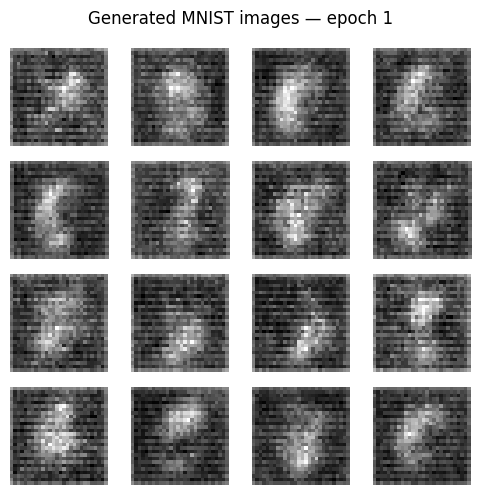

Epoch 02/15 | G loss: 1.0316 | D loss: 0.9134 | Time: 0.04 min
Epoch 03/15 | G loss: 0.9365 | D loss: 1.1218 | Time: 0.04 min
Epoch 04/15 | G loss: 0.8488 | D loss: 1.2485 | Time: 0.03 min
Epoch 05/15 | G loss: 0.8252 | D loss: 1.2777 | Time: 0.03 min


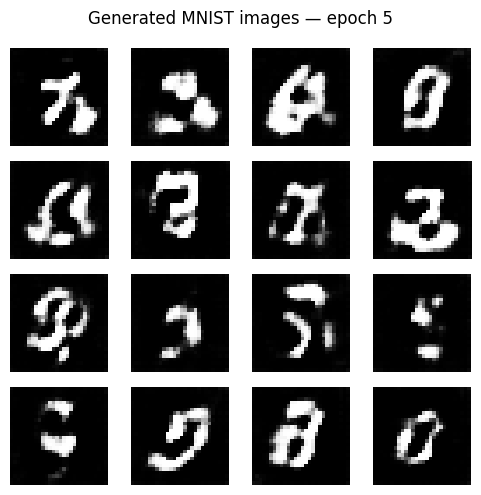

Epoch 06/15 | G loss: 0.8251 | D loss: 1.2677 | Time: 0.03 min
Epoch 07/15 | G loss: 0.8273 | D loss: 1.2620 | Time: 0.04 min
Epoch 08/15 | G loss: 0.8275 | D loss: 1.2578 | Time: 0.04 min
Epoch 09/15 | G loss: 0.8508 | D loss: 1.2335 | Time: 0.04 min
Epoch 10/15 | G loss: 0.8573 | D loss: 1.2287 | Time: 0.03 min


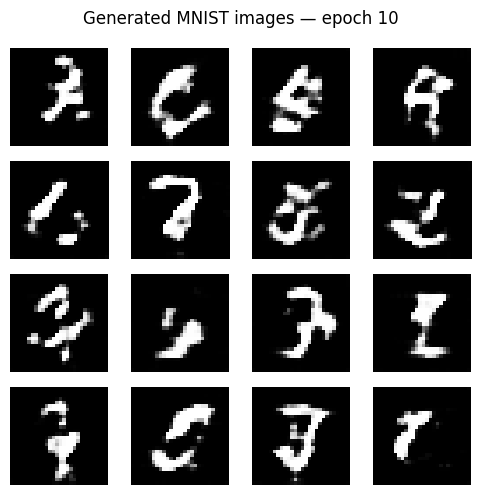

Epoch 11/15 | G loss: 0.8758 | D loss: 1.2151 | Time: 0.03 min
Epoch 12/15 | G loss: 0.8895 | D loss: 1.2001 | Time: 0.03 min
Epoch 13/15 | G loss: 0.8973 | D loss: 1.1935 | Time: 0.03 min
Epoch 14/15 | G loss: 0.8889 | D loss: 1.2063 | Time: 0.04 min
Epoch 15/15 | G loss: 0.8739 | D loss: 1.2229 | Time: 0.04 min


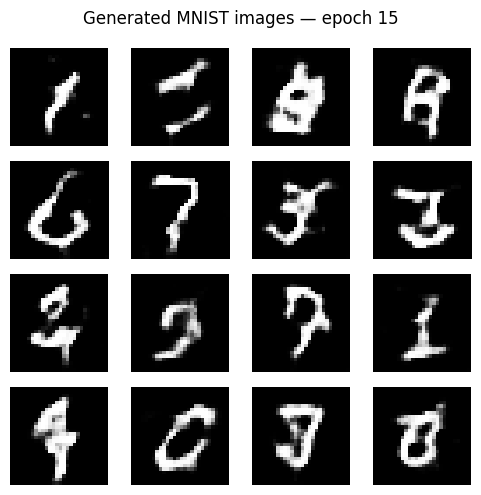

In [8]:
EPOCHS = 15
generator_losses = []
discriminator_losses = []
epoch_times = []

for epoch in range(1, EPOCHS + 1):
    start_time = time.time()
    gen_metric = keras.metrics.Mean()
    disc_metric = keras.metrics.Mean()

    for image_batch in train_ds:
        gen_loss_value, disc_loss_value = train_step(image_batch)
        gen_metric.update_state(gen_loss_value)
        disc_metric.update_state(disc_loss_value)

    g_loss = float(gen_metric.result().numpy())
    d_loss = float(disc_metric.result().numpy())
    elapsed = time.time() - start_time

    generator_losses.append(g_loss)
    discriminator_losses.append(d_loss)
    epoch_times.append(elapsed)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"G loss: {g_loss:.4f} | D loss: {d_loss:.4f} | "
        f"Time: {elapsed/60:.2f} min"
    )

    if epoch in [1, 5, 10, EPOCHS]:
        show_generated_images(generator, epoch)

## 9. Plot Generator and Discriminator loss curves

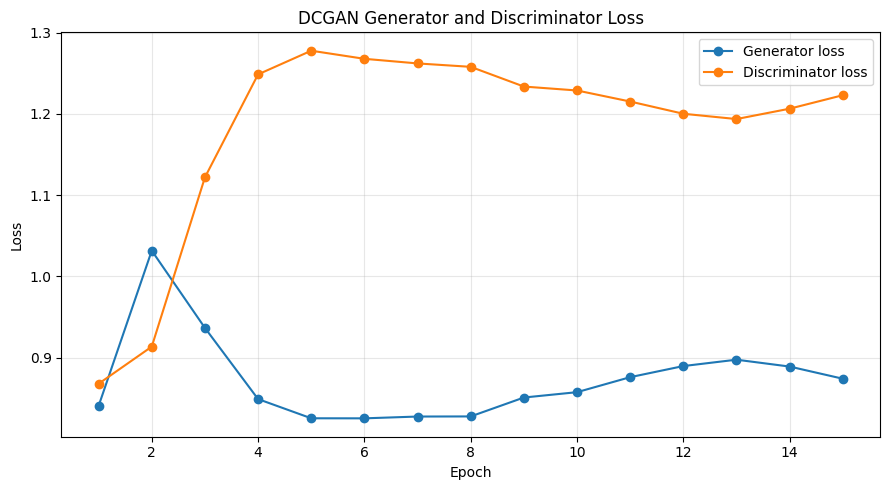

Total training time: 0.64 minutes


In [9]:
plt.figure(figsize=(9, 5))
plt.plot(range(1, len(generator_losses) + 1), generator_losses, marker="o", label="Generator loss")
plt.plot(range(1, len(discriminator_losses) + 1), discriminator_losses, marker="o", label="Discriminator loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("DCGAN Generator and Discriminator Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Total training time: {sum(epoch_times)/60:.2f} minutes")

## 10. Generate a final batch of synthetic images
The generated images are the model's outputs from random latent vectors. Compare their digit shapes and clarity with the real MNIST examples shown earlier.

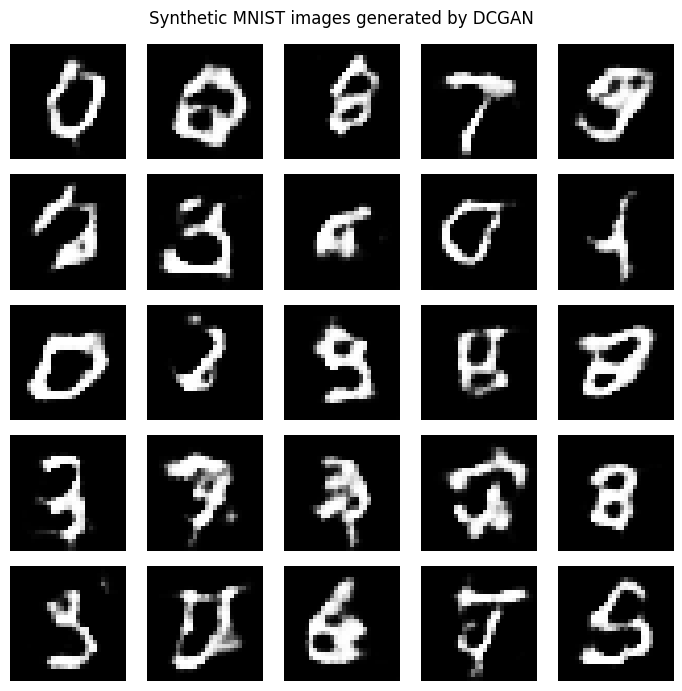

In [10]:
final_noise = tf.random.normal([25, LATENT_DIM], seed=123)
final_images = generator(final_noise, training=False)
final_images = (final_images + 1.0) / 2.0

plt.figure(figsize=(7, 7))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(final_images[i, :, :, 0], cmap="gray")
    plt.axis("off")
plt.suptitle("Synthetic MNIST images generated by DCGAN")
plt.tight_layout()
plt.show()

## 11. Save trained models and loss history

In [11]:
os.makedirs("dcgan_outputs", exist_ok=True)
generator.save("dcgan_outputs/mnist_generator.keras")
discriminator.save("dcgan_outputs/mnist_discriminator.keras")

loss_history = np.column_stack([
    np.arange(1, len(generator_losses) + 1),
    generator_losses,
    discriminator_losses,
    epoch_times
])
np.savetxt(
    "dcgan_outputs/dcgan_loss_history.csv",
    loss_history,
    delimiter=",",
    header="epoch,generator_loss,discriminator_loss,epoch_time_seconds",
    comments=""
)

print("Saved Generator, Discriminator and loss history.")

Saved Generator, Discriminator and loss history.


## 12. Observations and conclusion

After executing the notebook, record observations based on the generated image grids and loss curves.

- **Generator:** Learns to create digit-like images from random latent vectors.
- **Discriminator:** Learns to distinguish real MNIST images from generated images.
- **Generated-image quality:** Inspect whether digits are recognizable, varied and reasonably well-formed.
- **Loss curves:** GAN losses may fluctuate; they do not necessarily decrease smoothly. Interpret them together with generated-image quality.

**Conclusion:** A DCGAN is implemented using a Generator and Discriminator trained adversarially on a subset of MNIST. Synthetic images are generated and training behaviour is analyzed through loss curves and visual inspection.